In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_ids = list(range(0, 8+1))
# file_ids = [2]
plot_id = 2

dims = 16

In [4]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, file_ids, with_whisking=True)

# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t - 1, :] + spikes[t, :]
	return trace

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(reconstruct_calcium(trace.values, fs=sr), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
classes = [pd.DataFrame(
	cb[['running_speed']].values > np.quantile(cb[['running_speed']].values, 0.05),
	columns=['run']
) for cb in continuous_behaviors]

In [5]:
plot_idx = file_ids.index(plot_id)

In [6]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, scale=False,
												 n_pc=dims)

In [7]:
save = True

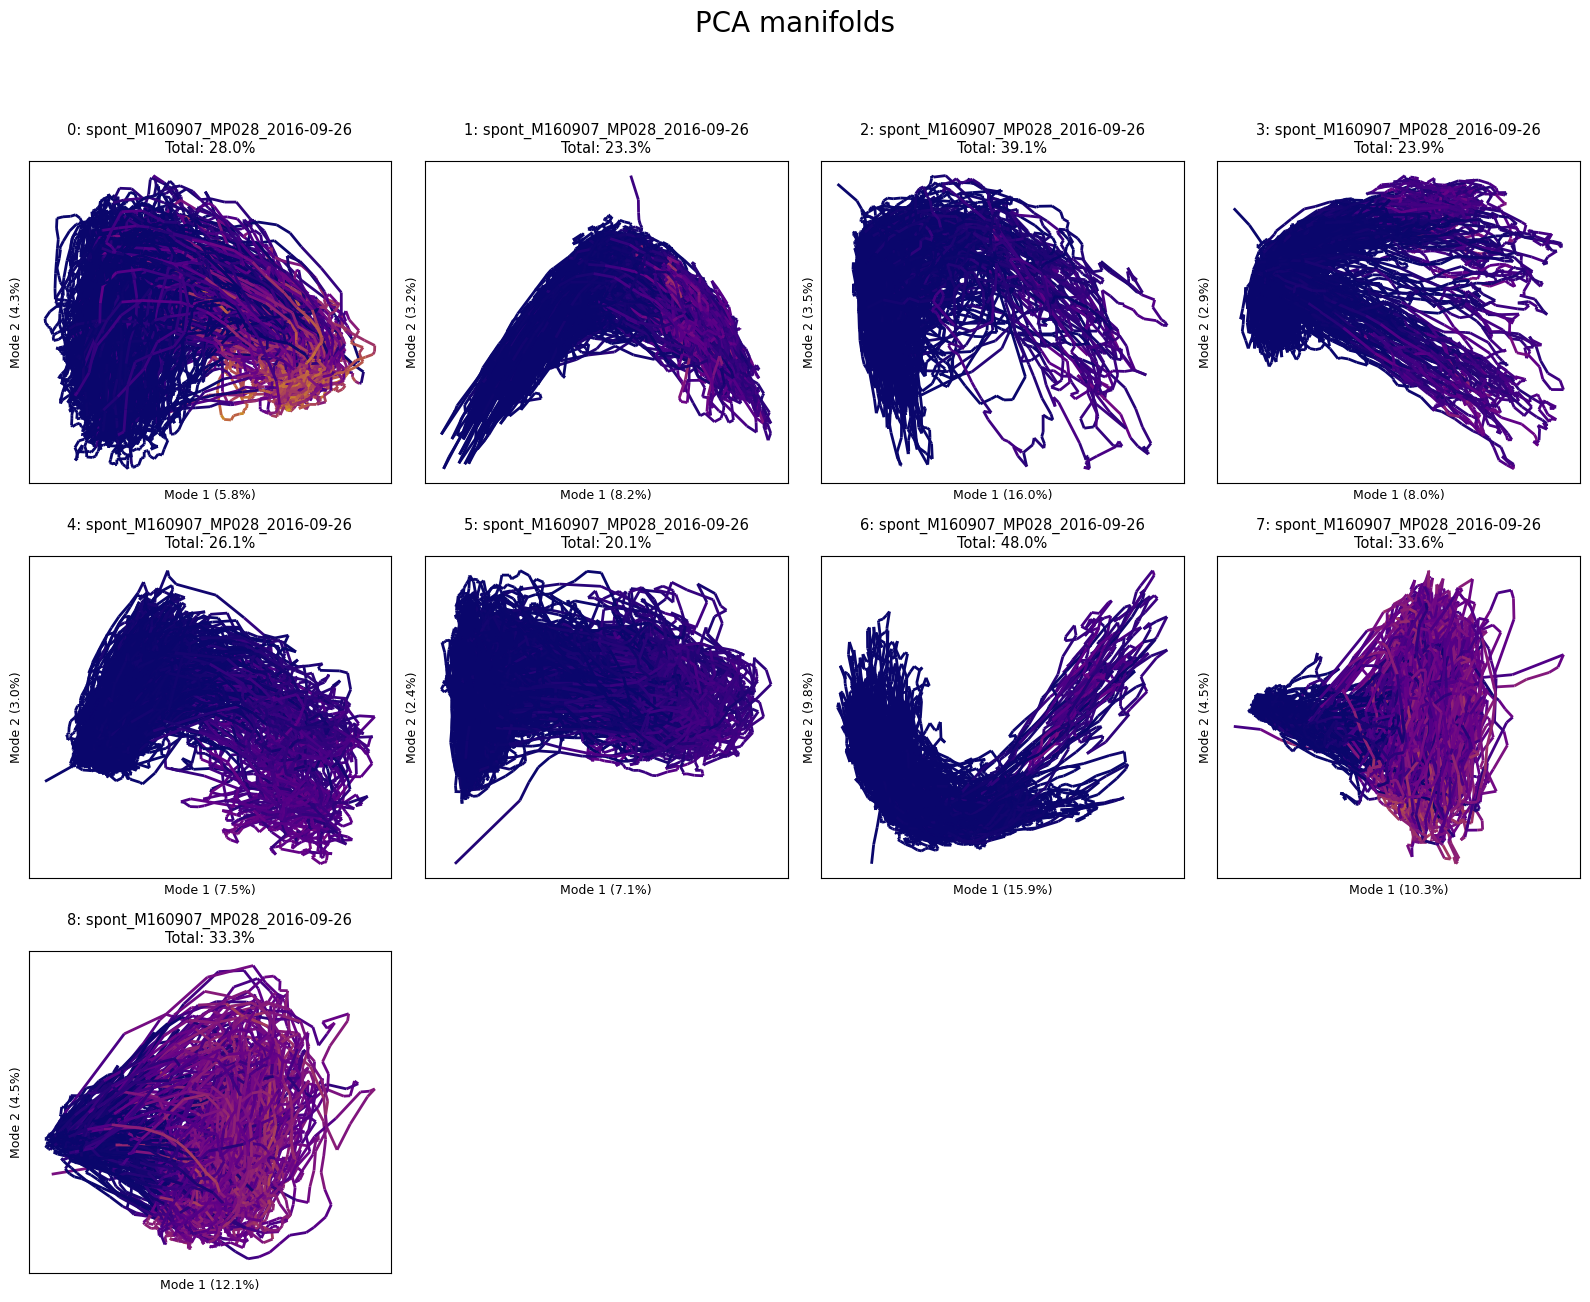

30.6%


In [8]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
						  modes_manifold, [cb[['running_speed']] for cb in continuous_behaviors],
						  [vx for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=1,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_running' if save else None)

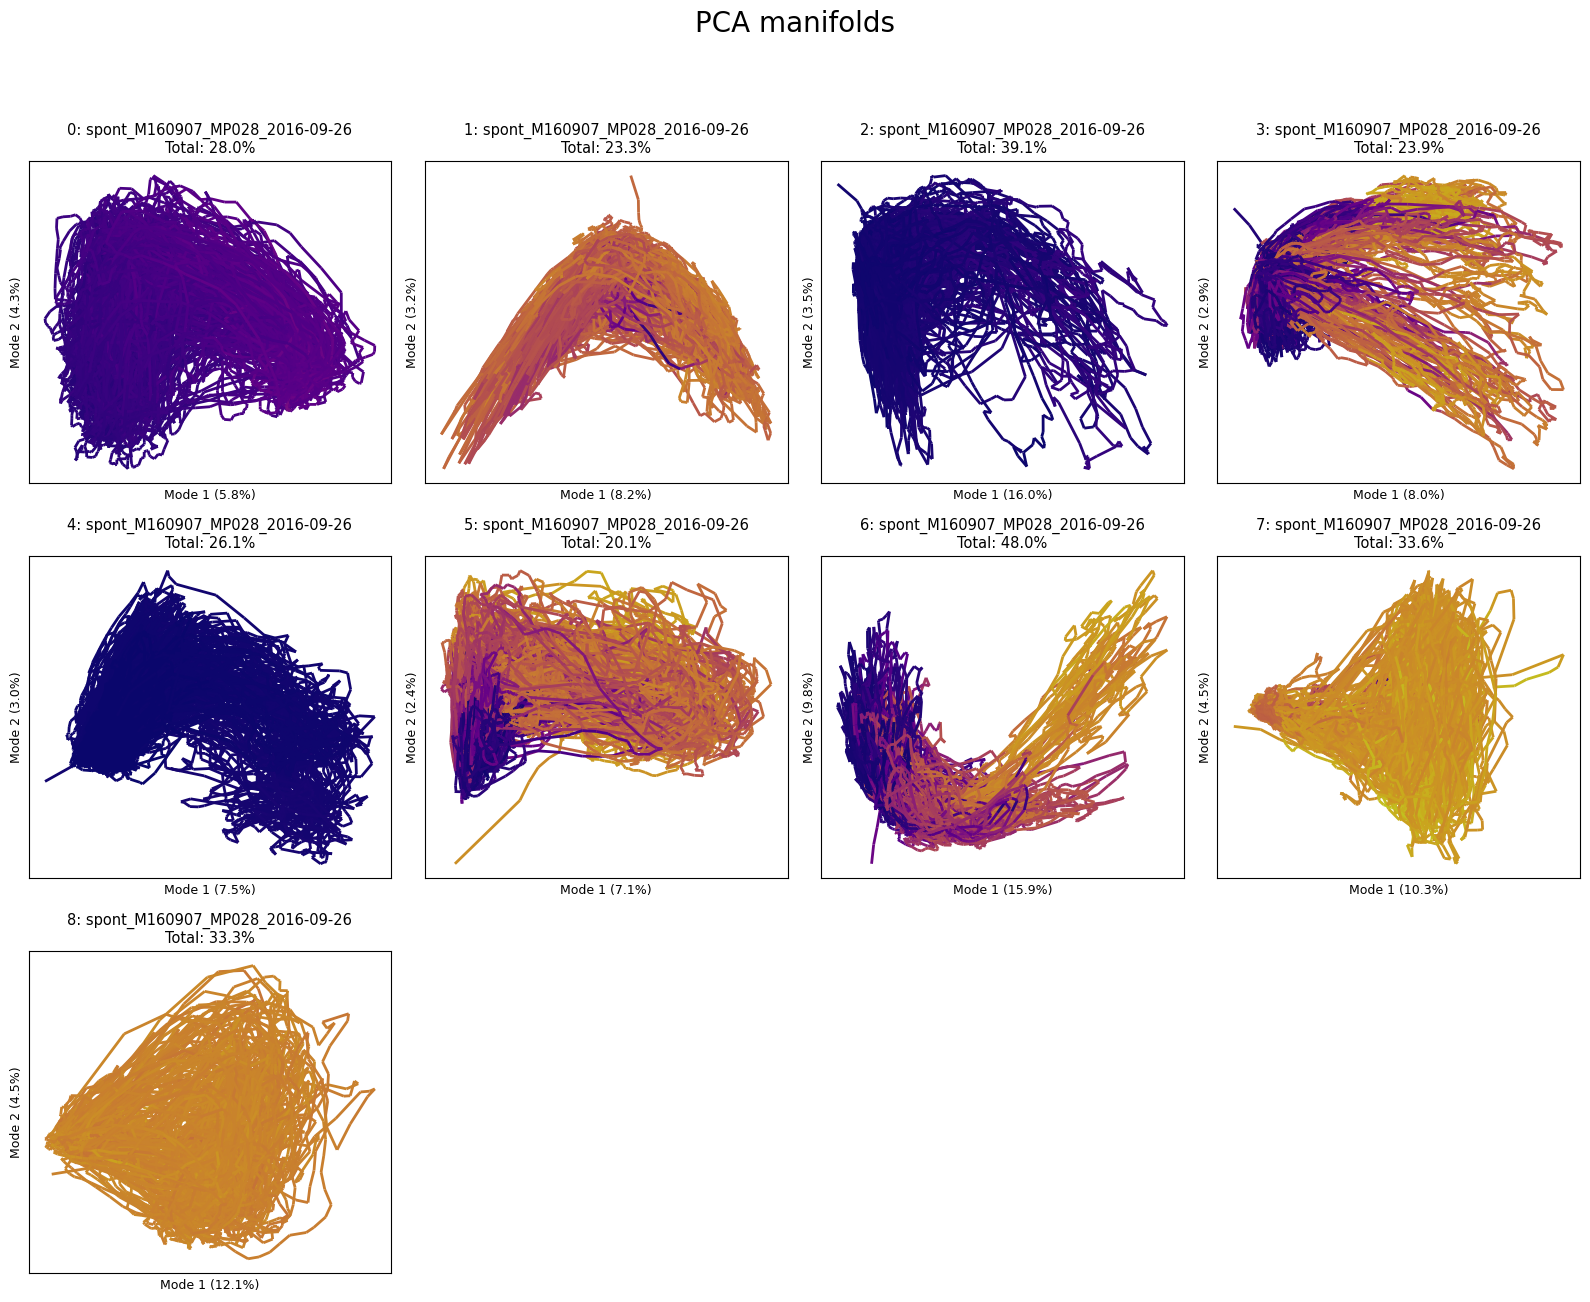

30.6%


In [9]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
						  modes_manifold, [cb[['pupil_area']] for cb in continuous_behaviors],
						  [vx for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=1,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_pupil' if save else None)

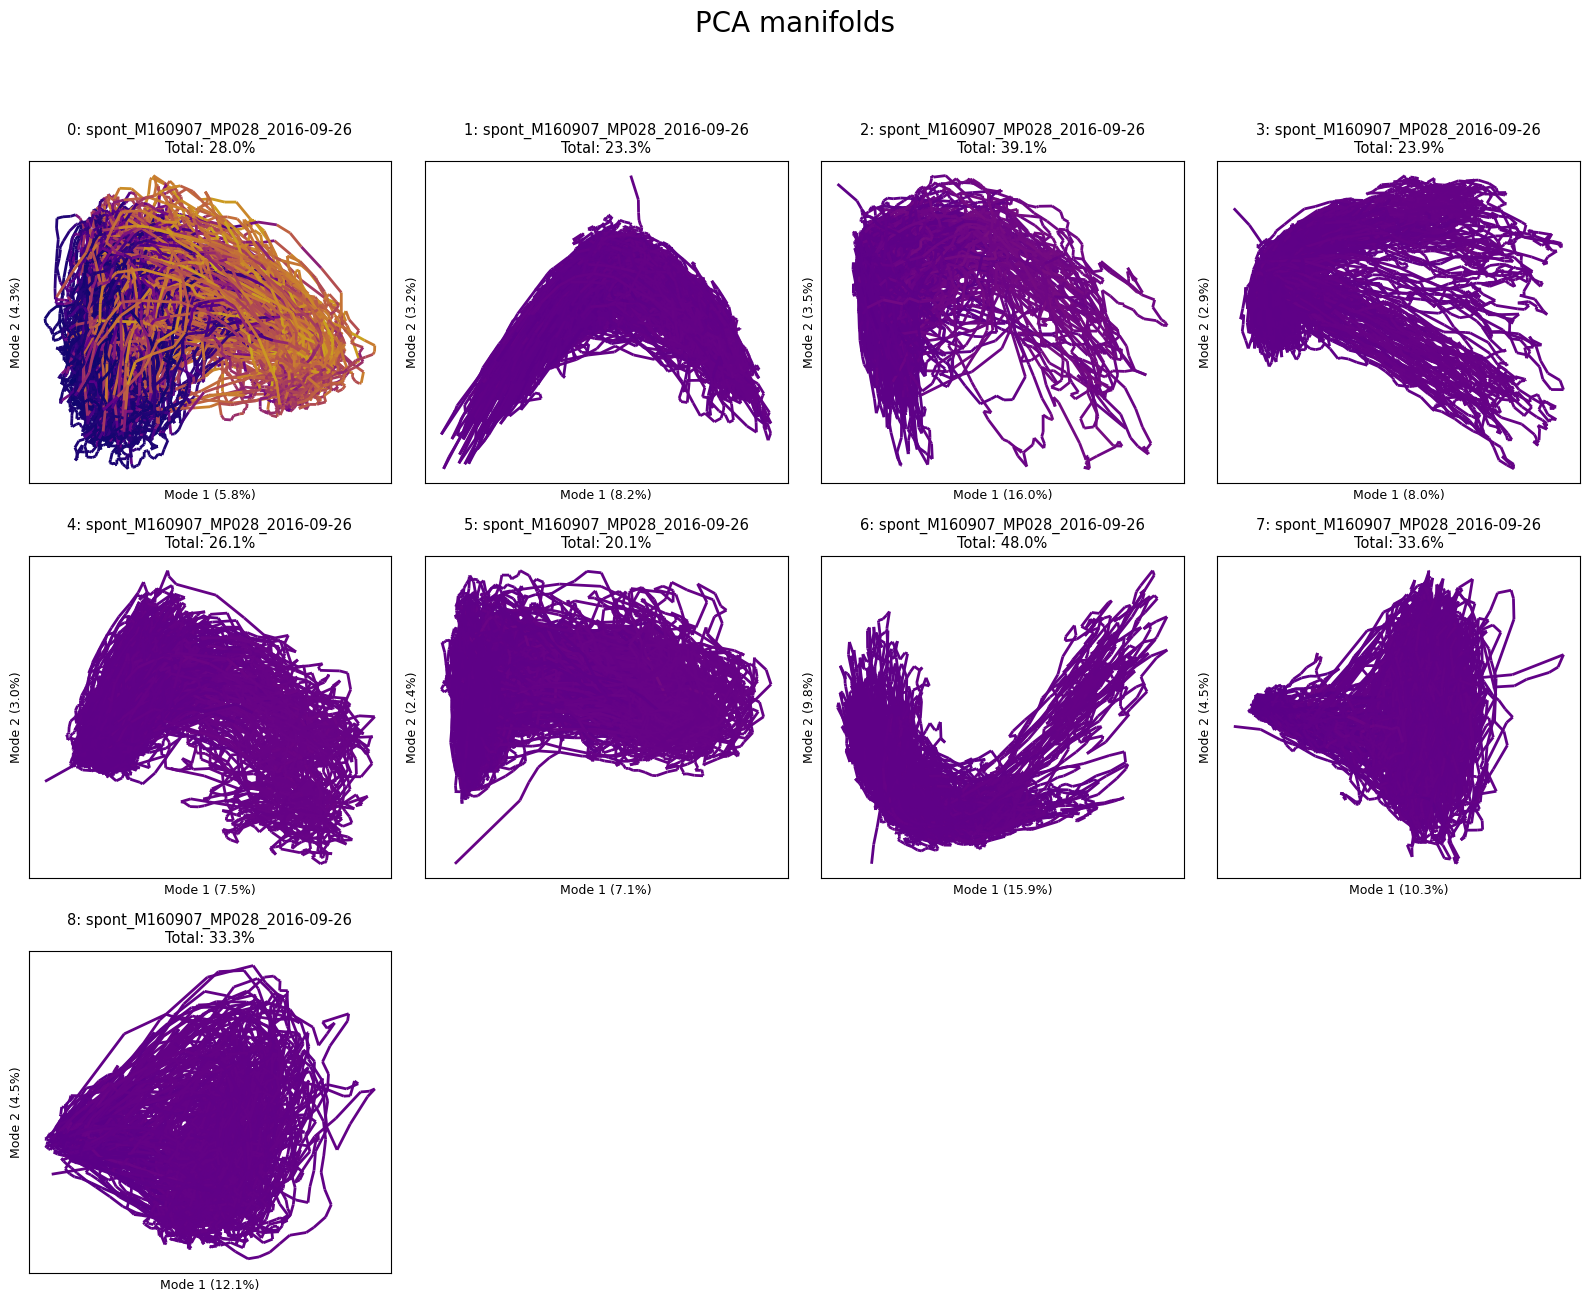

30.6%


In [10]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
						  modes_manifold, [cb[['whisking']] for cb in continuous_behaviors],
						  [vx for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=1,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_whisking' if save else None)

In [11]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 								 modes_manifold, None,
# 								 [vx[:3] for vx in vars_expl_mans], None,
# 								  titles=['PCA manifolds'] * len(file_ids), top_space=1, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [12]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 44.81272   35.17631   30.372662 ... 212.94128  341.95197   18.406395]
[179.557     97.458206 196.20226  ... 249.53203  262.06366  226.53815 ]
[ 17.543282  46.798737  18.869081 ...  85.27204   84.616165 124.72359 ]
[156.49431 206.86983 202.2139  ...   0.        0.        0.     ]
[ 59.4019    58.474785 101.938095 ... 193.9325   171.41719  179.35057 ]
[143.51428   84.147896 110.51263  ... 164.88939  126.943596 176.80467 ]
[ 91.24341   35.72524   34.787533 ... 208.51984   74.022896  66.519585]
[ 38.67458 285.63208  39.13184 ... 133.46706  68.29636  52.93583]
[ 43.885616  38.953777  47.667553 ... 134.66983  129.9529   163.18053 ]


In [ ]:
traces_residuals = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residuals):
	print(np.mean(trace.values, axis=0))

In [ ]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

# traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
#
# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

In [ ]:
# plot_utils.plot_heatmap_stack(traces[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
# 							  None,
# 							  label_traces='Neuronal activity', label_behavior=None,
# 							  height_ratios=(0, 1),
# 							  zlimits_activity=(0, 500), cmap='viridis')

In [ ]:
# plot_utils.plot_heatmap_stack(recos_manifold[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
# 							  None,
# 							  label_traces='manifold activity', label_behavior=None,
# 							  height_ratios=(0, 1),
# 							  zlimits_activity=(0, 500), cmap='viridis')

In [ ]:
# plot_utils.plot_heatmap_stack(traces_residuals[plot_idx].iloc[:, traces_manifolds_indices[plot_idx]].iloc[:, :1000],
# 							  None,
# 							  label_traces='residual activity', label_behavior=None,
# 							  height_ratios=(0, 1),
# 							  zlimits_activity=(0, 500), cmap='viridis')